# Long-context selective SSM on raw ICU EEG — HMS, v2

**Task:** HMS Harmful Brain Activity Classification (Seizure, LPD, GPD, LRDA, GRDA, Other), soft labels from expert votes.

**Changes from v1**
1. **Context sweep** — Mamba vs Transformer at 50/100/200/400 s of context (GRU and CNN at 50 s as references). Runs are saved one by one and skipped on rerun, so the sweep can span several Kaggle sessions.
2. **Two-stage training** — stage 1 on all rows, stage 2 fine-tunes on high-agreement rows (≥10 votes). Both stages are reported.
3. **Regularisation** — residual dropout in the SSM and CNN blocks (v1 Mamba overfit hardest); 10 epochs instead of 15.
4. **Leaner pure-PyTorch SSD** — B and C are shared across heads (Mamba-2 `ngroups=1`) instead of being copied per head. Optional gradient checkpointing for every model; optional official `mamba-ssm` kernels.
5. **Token-budget micro-batching** — long contexts use smaller micro-batches with gradient accumulation, so the effective batch stays at 64 for every context length.
6. **Streaming benchmark** — per-token cost and state memory for continuous monitoring over 15 min → 72 h of history: causal Mamba-2 (fixed state) vs Transformer (growing KV cache) vs GRU (fixed state).

**Kaggle setup:** Add Input → Competitions → *HMS - Harmful Brain Activity Classification*. GPU T4 (needed for `USE_OFFICIAL_MAMBA2`; P100 works for everything else). For a long sweep use **Save Version → Save & Run All** (runs up to 12 h in the background and keeps `/kaggle/working`). To resume in a later session, add this notebook's output as an input: finished runs are picked up from it and skipped.

In [1]:
import os, glob, json, math, time, random, shutil
import numpy as np
import pandas as pd

CFG = dict(
    DATA_ROOT=None,                       # None = auto-detect under /kaggle/input
    CACHE_DIR="/kaggle/working/cache",    # replaced in the v2 settings cell below
    RESULTS_DIR="/kaggle/working/results",
    FS=100,                               # target sampling rate (Hz)
    CTX_SEC=50,
    CACHE_CTX_SEC=100,
    JITTER_SEC=1.0,                       # train-time random shift of the window centre
    PATCH=25,                             # samples per token (0.25 s at 100 Hz)
    N_FOLDS=5, FOLDS=[0], SEED=42,
    MODELS=["mamba", "transformer", "gru", "cnn"],
    D_MODEL=128, N_LAYERS=4, D_STATE=64, HEADDIM=32, EXPAND=2, CHUNK=64, N_HEADS_ATTN=4,
    EPOCHS=15, BATCH=64, LR=1e-3, WD=0.05, WARMUP_FRAC=0.05, CLIP=1.0,
    TRAIN_MIN_VOTES=0,
    HIGH_VOTE=10,                         # threshold for the high-agreement evaluation subset
    NUM_WORKERS=4, AMP=True,
    USE_OFFICIAL_MAMBA2=False,
    RUN_BENCHMARK=True,
    BENCH_CTX=[50, 100, 200, 400, 600, 1200],
)

In [2]:
import pyarrow.parquet as pq
import multiprocessing as mp
from scipy.signal import butter, sosfiltfilt
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, f1_score
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, Sampler

def seed_all(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_all(CFG["SEED"])
MP = mp.get_context("fork")   # Kaggle is Linux; fork shares globals with workers
DEV = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", DEV, torch.cuda.get_device_name(0) if DEV.type == "cuda" else "")

def find_root():
    if CFG["DATA_ROOT"]:
        return CFG["DATA_ROOT"]
    for pat in ["/kaggle/input/*/train.csv", "/kaggle/input/*/*/train.csv"]:
        for h in glob.glob(pat):
            if os.path.isdir(os.path.join(os.path.dirname(h), "train_eegs")):
                return os.path.dirname(h)
    raise FileNotFoundError("Attach the competition data: Add Input → Competitions → HMS - Harmful Brain Activity Classification")

ROOT = find_root()
print("data:", ROOT)

device: cuda Tesla T4
data: /kaggle/input/competitions/hms-harmful-brain-activity-classification


## Labels and patient-level folds

In [3]:
VOTES = ["seizure_vote", "lpd_vote", "gpd_vote", "lrda_vote", "grda_vote", "other_vote"]
CLASSES = ["Seizure", "LPD", "GPD", "LRDA", "GRDA", "Other"]

df = pd.read_csv(f"{ROOT}/train.csv")
df["n_votes"] = df[VOTES].sum(axis=1)
P_COLS = [f"p_{c}" for c in CLASSES]
df[P_COLS] = df[VOTES].div(df["n_votes"], axis=0).to_numpy()
df["y"] = df[P_COLS].to_numpy().argmax(1)
df["center"] = df["eeg_label_offset_seconds"] + 25.0   # experts labelled the central 10 s of each 50 s window

sgkf = StratifiedGroupKFold(n_splits=CFG["N_FOLDS"], shuffle=True, random_state=CFG["SEED"])
df["fold"] = -1
for k, (_, va) in enumerate(sgkf.split(df, df["y"], groups=df["patient_id"])):
    df.loc[df.index[va], "fold"] = k
assert df.groupby("patient_id")["fold"].nunique().max() == 1, "patient leaked across folds"

print(f"rows={len(df):,}  eegs={df.eeg_id.nunique():,}  patients={df.patient_id.nunique():,}")
print(df.groupby("fold").agg(rows=("eeg_id", "size"), eegs=("eeg_id", "nunique"), patients=("patient_id", "nunique")))
print(df.drop_duplicates("eeg_id")["expert_consensus"].value_counts())

rows=106,800  eegs=17,089  patients=1,950
       rows  eegs  patients
fold                       
0     17085  2795       383
1     25502  3689       386
2     21174  3585       394
3     22141  3238       397
4     20898  3782       390
expert_consensus
Other      7196
Seizure    2785
LPD        2577
GRDA       1828
GPD        1787
LRDA        916
Name: count, dtype: int64


## Preprocessing
18-channel bipolar double banana + midline (identical to I-CARE's 18 bipolar pairs). Band-pass 0.5–40 Hz at 200 Hz, then every second sample (100 Hz; the 40 Hz low-pass prevents aliasing). Amplitudes stay in µV (no per-window z-scoring), because absolute voltage — suppression, high-amplitude discharges — is clinically informative.

In [4]:
BIPOLAR = [("Fp1", "F7"), ("F7", "T3"), ("T3", "T5"), ("T5", "O1"),    # left temporal chain
           ("Fp2", "F8"), ("F8", "T4"), ("T4", "T6"), ("T6", "O2"),    # right temporal chain
           ("Fp1", "F3"), ("F3", "C3"), ("C3", "P3"), ("P3", "O1"),    # left parasagittal chain
           ("Fp2", "F4"), ("F4", "C4"), ("C4", "P4"), ("P4", "O2"),    # right parasagittal chain
           ("Fz", "Cz"), ("Cz", "Pz")]                                 # midline
FLIP_PERM = [4, 5, 6, 7, 0, 1, 2, 3, 12, 13, 14, 15, 8, 9, 10, 11, 16, 17]   # left <-> right hemisphere
ELECTRODES = sorted({e for pair in BIPOLAR for e in pair})
N_CH = len(BIPOLAR)
SRC_FS = 200
SOS = butter(4, [0.5, 40.0], btype="band", fs=SRC_FS, output="sos")
CLIP_UV = 500.0

def load_bipolar(path):
    d = pd.read_parquet(path, columns=ELECTRODES)
    d = d.interpolate(limit_direction="both").fillna(0.0)
    a = d.to_numpy(np.float32)
    col = {c: i for i, c in enumerate(ELECTRODES)}
    x = np.stack([a[:, col[p]] - a[:, col[q]] for p, q in BIPOLAR], axis=1)
    x = sosfiltfilt(SOS, x, axis=0)
    return np.clip(x, -CLIP_UV, CLIP_UV).astype(np.float32)

def _nrows(eid):
    return pq.ParquetFile(f"{ROOT}/train_eegs/{eid}.parquet").metadata.num_rows

def plan_cache(df, half_sec):
    g = df.groupby("eeg_id")["center"].agg(["min", "max"]).reset_index()
    with MP.Pool(CFG["NUM_WORKERS"]) as pool:
        n = pool.map(_nrows, g["eeg_id"].tolist(), chunksize=64)
    g["n_src"] = n
    s0 = np.floor((g["min"] - half_sec) * SRC_FS).clip(lower=0).astype(np.int64)
    s0 -= s0 % 2
    s1 = np.minimum(g["n_src"], np.ceil((g["max"] + half_sec) * SRC_FS)).astype(np.int64)
    g["s0"], g["length"] = s0, ((s1 - s0 + 1) // 2).clip(lower=0)
    g["offset"] = np.concatenate([[0], np.cumsum(g["length"].to_numpy())[:-1]])
    return g[["eeg_id", "n_src", "s0", "length", "offset"]]

def _build_one(args):
    eid, s0, length = args
    x = load_bipolar(f"{ROOT}/train_eegs/{eid}.parquet")[s0::2][:length]
    out = np.zeros((length, N_CH), np.float16)
    out[:len(x)] = x
    return out

def build_cache(df):
    meta_path = f"{CFG['CACHE_DIR']}/meta.json"
    want = dict(cache_ctx=CFG["CACHE_CTX_SEC"], jitter=CFG["JITTER_SEC"], fs=CFG["FS"], n_eegs=int(df.eeg_id.nunique()))
    if os.path.exists(meta_path) and json.load(open(meta_path)) == want:
        print("cache found, reusing")
        return pd.read_csv(f"{CFG['CACHE_DIR']}/index.csv")
    half = CFG["CACHE_CTX_SEC"] / 2 + CFG["JITTER_SEC"]
    idx = plan_cache(df, half)
    total = int(idx["length"].sum())
    need = total * N_CH * 2
    free = shutil.disk_usage(CFG["CACHE_DIR"]).free
    print(f"cache: {total/CFG['FS']/3600:,.1f} h of EEG, {need/1e9:.2f} GB needed, {free/1e9:.1f} GB free")
    if need > 0.9 * free:
        raise RuntimeError("Not enough disk: lower CACHE_CTX_SEC or point CACHE_DIR at a larger disk")
    mm = np.lib.format.open_memmap(f"{CFG['CACHE_DIR']}/signals.npy", mode="w+", dtype=np.float16, shape=(total, N_CH))
    jobs = list(zip(idx["eeg_id"], idx["s0"], idx["length"]))
    t0 = time.time()
    with MP.Pool(CFG["NUM_WORKERS"]) as pool:
        for i, (x, off) in enumerate(zip(pool.imap(_build_one, jobs, chunksize=16), idx["offset"])):
            mm[off:off + len(x)] = x
            if i % 2000 == 0:
                print(f"  {i:,}/{len(jobs):,}  {time.time()-t0:.0f}s")
    mm.flush(); del mm
    idx.to_csv(f"{CFG['CACHE_DIR']}/index.csv", index=False)
    json.dump(want, open(meta_path, "w"))
    print(f"cache built in {time.time()-t0:.0f}s")
    return idx

## Dataset
Each item is a `CTX_SEC` window centred on the labelled 10 s. Positions outside the recording are zero-filled and flagged in a mask; the SSM treats masked steps as identity transitions (Δ = 0), the Transformer ignores them via key-padding, the readout never pools them.
Training samples one random sub-window per EEG per epoch, so long recordings with many overlapping sub-windows don't dominate. Validation uses the middle sub-window of each EEG (the competition test set also has one row per EEG).

In [5]:
class HMSDataset(Dataset):
    """Self-contained (no notebook globals in __getitem__), so it works with any worker start method."""
    def __init__(self, rows, ctx_sec, train):
        assert ctx_sec <= CFG["CACHE_CTX_SEC"], "CTX_SEC exceeds the cached context; rebuild the cache"
        self.eid = rows["eeg_id"].to_numpy()
        self.center = rows["center"].to_numpy(np.float64)
        self.p = rows[P_COLS].to_numpy(np.float32)
        self.y = rows["y"].to_numpy()
        self.fs, self.src_fs, self.n_ch = CFG["FS"], SRC_FS, N_CH
        self.n = int(ctx_sec * self.fs)
        assert self.n % CFG["PATCH"] == 0
        self.train, self.jitter, self.flip = train, CFG["JITTER_SEC"], np.array(FLIP_PERM)
        self.cache = {int(e): CACHE[int(e)] for e in np.unique(self.eid)}
        self.path = f"{CFG['CACHE_DIR']}/signals.npy"
        self.mm = None

    def __len__(self):
        return len(self.eid)

    def __getitem__(self, i):
        if self.mm is None:                      # open lazily so each worker gets its own handle
            self.mm = np.load(self.path, mmap_mode="r")
        off, s0, length = self.cache[int(self.eid[i])]
        c = self.center[i]
        if self.train:
            c += np.random.uniform(-self.jitter, self.jitter)
        i0 = int(round((c - self.n / self.fs / 2 - s0 / self.src_fs) * self.fs))
        x = np.zeros((self.n, self.n_ch), np.float32)
        m = np.zeros(self.n, np.float32)
        a, b = max(i0, 0), min(i0 + self.n, length)
        if b > a:
            x[a - i0:b - i0] = self.mm[off + a:off + b]
            m[a - i0:b - i0] = 1.0
        x = x.T / 50.0                           # ~unit scale while keeping absolute amplitude
        if self.train:
            if np.random.rand() < 0.5:
                x = x[self.flip]
            x = x * np.random.uniform(0.9, 1.1)
        return torch.from_numpy(np.ascontiguousarray(x)), torch.from_numpy(m), torch.from_numpy(self.p[i]), int(self.y[i])

class OnePerEEG(Sampler):
    def __init__(self, eids, seed):
        order = np.argsort(eids, kind="stable")
        _, starts = np.unique(eids[order], return_index=True)
        self.groups = np.split(order, starts[1:])
        self.seed, self.epoch = seed, 0
    def __len__(self):
        return len(self.groups)
    def __iter__(self):
        rng = np.random.default_rng(self.seed + self.epoch); self.epoch += 1
        idx = np.array([g[rng.integers(len(g))] for g in self.groups])
        rng.shuffle(idx)
        return iter(idx.tolist())

def middle_row_per_eeg(rows):
    rows = rows.sort_values(["eeg_id", "eeg_label_offset_seconds"])
    g = rows.groupby("eeg_id")
    return rows[g.cumcount().to_numpy() == (g["eeg_id"].transform("size") // 2).to_numpy()]

## v2 settings
Everything from here down is also the **append set**: in a live v1 session you can paste these cells at the end and run them; they reuse the data, folds and preprocessing already loaded and redefine everything that changed.

**Compute budget (rough, T4, pure-PyTorch SSD):** v1 Mamba took ~63 s/epoch at 50 s of context and cost scales roughly linearly with context, so the fold-0 sweep (Mamba + Transformer at 50/100/200/400 s, plus GRU/CNN at 50 s) is several hours. `TIME_BUDGET_H` stops launching new runs before Kaggle's 12 h limit; rerun to continue. Check the first epoch time printed for each run and adjust `SWEEP_CTX` if needed.

In [6]:
CFG.update(dict(
    CACHE_CTX_SEC=400,                         # largest context in SWEEP_CTX (rebuilds the cache once)
    CACHE_DIR="/tmp/hms_cache",                # not saved with the output; rebuilt per session (~10–20 min)
    RESULTS_DIR="/kaggle/working/results_v2",
    PREV_RESULTS_GLOBS=["/kaggle/input/*/results_v2/*.json", "/kaggle/input/*/*/results_v2/*.json"],
    SWEEP_MODELS=["mamba", "transformer"],
    SWEEP_CTX=[50, 100, 200, 400],
    REFERENCE_MODELS=["gru", "cnn"],           # trained at 50 s only
    SWEEP_FOLDS=[0],                           # add folds once the fold-0 trend is clear
    EPOCHS=10, STAGE2_EPOCHS=3, STAGE2_LR=2e-4, STAGE2_MIN_VOTES=10,
    DROPOUT=0.1,
    TOKENS_PER_BATCH=25600,                    # micro-batch = min(BATCH, budget // tokens per sample); effective batch stays BATCH
    GRAD_CKPT=False,                           # True = gradient checkpointing for every model (less memory, slower)
    TIME_BUDGET_H=11.0,                        # stop launching new runs after this many hours
    USE_OFFICIAL_MAMBA2=False,                 # True = fused mamba-ssm kernels (Internet on, GPU T4); first check the "official vs pure" check below
    RUN_BENCHMARK=True,
    BENCH_CTX=[50, 100, 200, 400, 600, 1200],
    BENCH_CKPT=[False, True],
    RUN_STREAM_BENCH=True,
    STREAM_HOURS=[0.25, 1, 6, 24, 72],
))
CFG_OVERRIDES = {}                             # quick overrides, e.g. {"SWEEP_CTX": [50, 100], "EPOCHS": 2}
CFG.update(CFG_OVERRIDES)
T_START = time.time()
os.makedirs(CFG["CACHE_DIR"], exist_ok=True)
os.makedirs(CFG["RESULTS_DIR"], exist_ok=True)
if CFG["CACHE_DIR"] != "/kaggle/working/cache" and os.path.isdir("/kaggle/working/cache"):
    shutil.rmtree("/kaggle/working/cache")    # v1 cache (100 s context) is superseded; free the space
    print("removed v1 cache")
print(json.dumps(CFG, indent=1))

{
 "DATA_ROOT": null,
 "CACHE_DIR": "/tmp/hms_cache",
 "RESULTS_DIR": "/kaggle/working/results_v2",
 "FS": 100,
 "CTX_SEC": 50,
 "CACHE_CTX_SEC": 400,
 "JITTER_SEC": 1.0,
 "PATCH": 25,
 "N_FOLDS": 5,
 "FOLDS": [
  0
 ],
 "SEED": 42,
 "MODELS": [
  "mamba",
  "transformer",
  "gru",
  "cnn"
 ],
 "D_MODEL": 128,
 "N_LAYERS": 4,
 "D_STATE": 64,
 "HEADDIM": 32,
 "EXPAND": 2,
 "CHUNK": 64,
 "N_HEADS_ATTN": 4,
 "EPOCHS": 10,
 "BATCH": 64,
 "LR": 0.001,
 "WD": 0.05,
 "WARMUP_FRAC": 0.05,
 "CLIP": 1.0,
 "TRAIN_MIN_VOTES": 0,
 "HIGH_VOTE": 10,
 "NUM_WORKERS": 4,
 "AMP": true,
 "USE_OFFICIAL_MAMBA2": false,
 "RUN_BENCHMARK": true,
 "BENCH_CTX": [
  50,
  100,
  200,
  400,
  600,
  1200
 ],
 "PREV_RESULTS_GLOBS": [
  "/kaggle/input/*/results_v2/*.json",
  "/kaggle/input/*/*/results_v2/*.json"
 ],
 "SWEEP_MODELS": [
  "mamba",
  "transformer"
 ],
 "SWEEP_CTX": [
  50,
  100,
  200,
  400
 ],
 "REFERENCE_MODELS": [
  "gru",
  "cnn"
 ],
 "SWEEP_FOLDS": [
  0
 ],
 "STAGE2_EPOCHS": 3,
 "STAGE2_LR": 0

In [7]:
if CFG["USE_OFFICIAL_MAMBA2"]:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-build-isolation",
                    "causal-conv1d", "mamba-ssm"], check=False)

In [8]:
cache_idx = build_cache(df)
CACHE = {int(r.eeg_id): (int(r.offset), int(r.s0), int(r.length)) for r in cache_idx.itertuples()}

cache: 380.3 h of EEG, 4.93 GB needed, 1126.1 GB free
  0/17,089  1s
  2,000/17,089  21s
  4,000/17,089  43s
  6,000/17,089  64s
  8,000/17,089  84s
  10,000/17,089  105s
  12,000/17,089  125s
  14,000/17,089  146s
  16,000/17,089  167s
cache built in 180s


## Models
All models: `Stem` (conv + 0.25 s patching → tokens) → sequence mixer → readout (pool over the central 10 s ⊕ pool over the full context) → 6 logits. Only the mixer differs.

The SSM is a bidirectional Mamba-2 block. `ssd()` is the chunked state-space-duality algorithm (exact); `ssd_reference()` is the plain recurrence used to verify it. `Mamba2.step()` is the recurrent form used for streaming.

In [9]:
from torch.utils.checkpoint import checkpoint

def run_block(blk, *args):
    if CFG["GRAD_CKPT"] and blk.training and torch.is_grad_enabled():
        return checkpoint(blk, *args, use_reentrant=False)
    return blk(*args)

def segsum(x):
    """x: (..., T) log-decays -> (..., T, T) with out[i, j] = sum_{k=j+1..i} x_k for i >= j, else -inf."""
    T = x.size(-1)
    x = x[..., None].expand(*x.shape, T)
    low = torch.tril(torch.ones(T, T, dtype=torch.bool, device=x.device), -1)
    x = x.masked_fill(~low, 0)
    s = torch.cumsum(x, dim=-2)
    keep = torch.tril(torch.ones(T, T, dtype=torch.bool, device=x.device), 0)
    return s.masked_fill(~keep, -torch.inf)

def ssd(X, A, B, C, chunk):
    """Selective SSM, chunked SSD form.  h_t = exp(A_t) h_{t-1} + X_t B_t^T,  y_t = h_t C_t
    X: (b, T, h, p) input already multiplied by dt;  A: (b, T, h) = dt * A (<= 0);
    B, C: (b, T, n), shared by all heads (Mamba-2 with ngroups = 1)."""
    b, T, h, p = X.shape
    pad = (-T) % chunk
    if pad:
        X = F.pad(X, (0, 0, 0, 0, 0, pad))
        B, C = F.pad(B, (0, 0, 0, pad)), F.pad(C, (0, 0, 0, pad))
        A = F.pad(A, (0, 0, 0, pad))
    c = (T + pad) // chunk
    X = X.reshape(b, c, chunk, h, p)
    B = B.reshape(b, c, chunk, -1)
    C = C.reshape(b, c, chunk, -1)
    A = A.reshape(b, c, chunk, h).permute(0, 3, 1, 2)            # (b, h, c, l)
    A_cs = torch.cumsum(A, dim=-1)
    L = torch.exp(segsum(A))                                     # (b, h, c, l, s)
    CB = torch.einsum("bcln,bcsn->bcls", C, B)
    Y_diag = torch.einsum("bcls,bhcls,bcshp->bclhp", CB, L, X)
    decay_states = torch.exp(A_cs[..., -1:] - A_cs)
    states = torch.einsum("bcln,bhcl,bclhp->bchpn", B, decay_states, X)
    states = torch.cat([torch.zeros_like(states[:, :1]), states], dim=1)
    decay_chunk = torch.exp(segsum(F.pad(A_cs[..., -1], (1, 0))))
    states = torch.einsum("bhzc,bchpn->bzhpn", decay_chunk, states)[:, :-1]
    Y_off = torch.einsum("bcln,bchpn,bhcl->bclhp", C, states, torch.exp(A_cs))
    return (Y_diag + Y_off).reshape(b, c * chunk, h, p)[:, :T]

def ssd_reference(X, A, B, C):
    b, T, h, p = X.shape
    state = X.new_zeros(b, h, p, B.size(-1))
    ys = []
    for t in range(T):
        state = torch.exp(A[:, t])[..., None, None] * state + X[:, t, :, :, None] * B[:, t, None, None, :]
        ys.append(torch.einsum("bhpn,bn->bhp", state, C[:, t]))
    return torch.stack(ys, 1)

class RMSNorm(nn.Module):
    def __init__(self, d, eps=1e-5):
        super().__init__(); self.w = nn.Parameter(torch.ones(d)); self.eps = eps
    def forward(self, x):
        return x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + self.eps) * self.w

class Mamba2(nn.Module):
    """Mamba-2 mixer (pure PyTorch). Masked steps get dt = 0: no decay, no input -> state passes through unchanged."""
    def __init__(self, d, d_state, headdim, expand, chunk, d_conv=4):
        super().__init__()
        self.di, self.n, self.p, self.chunk = expand * d, d_state, headdim, chunk
        self.h = self.di // headdim
        self.in_proj = nn.Linear(d, 2 * self.di + 2 * d_state + self.h, bias=False)
        cd = self.di + 2 * d_state
        self.conv = nn.Conv1d(cd, cd, d_conv, groups=cd, padding=d_conv - 1)
        dt = torch.exp(torch.rand(self.h) * (math.log(0.1) - math.log(1e-3)) + math.log(1e-3)).clamp(min=1e-4)
        self.dt_bias = nn.Parameter(dt + torch.log(-torch.expm1(-dt)))     # inverse softplus
        self.A_log = nn.Parameter(torch.log(torch.empty(self.h).uniform_(1, 16)))
        self.D = nn.Parameter(torch.ones(self.h))
        self.norm = RMSNorm(self.di)
        self.out_proj = nn.Linear(self.di, d, bias=False)

    def forward(self, u, m):
        b, T, _ = u.shape
        z, xBC, dt = torch.split(self.in_proj(u), [self.di, self.di + 2 * self.n, self.h], dim=-1)
        xBC = xBC * m[..., None]
        xBC = F.silu(self.conv(xBC.transpose(1, 2))[..., :T].transpose(1, 2))
        x, Bm, Cm = torch.split(xBC, [self.di, self.n, self.n], dim=-1)
        with torch.autocast(device_type=u.device.type, enabled=False):
            dt = F.softplus(dt.float() + self.dt_bias) * m[..., None]
            A = -torch.exp(self.A_log.float())
            x = x.float().reshape(b, T, self.h, self.p)
            y = ssd(x * dt[..., None], A * dt, Bm.float(), Cm.float(), self.chunk) + x * self.D[:, None]
        y = y.reshape(b, T, self.di).to(u.dtype)
        return self.out_proj(self.norm(y * F.silu(z)))

    def init_state(self, b, device):
        cd = self.di + 2 * self.n
        return (torch.zeros(b, cd, self.conv.kernel_size[0], device=device),
                torch.zeros(b, self.h, self.p, self.n, device=device))

    def step(self, u, state):
        """One token, u: (b, d). Fixed-size state: conv window (b, cd, d_conv) + SSM state (b, h, p, n)."""
        conv_st, ssm_st = state
        b = u.size(0)
        z, xBC, dt = torch.split(self.in_proj(u), [self.di, self.di + 2 * self.n, self.h], dim=-1)
        conv_st = torch.roll(conv_st, -1, dims=-1)
        conv_st[..., -1] = xBC.float()
        xBC = F.silu((conv_st * self.conv.weight[:, 0, :]).sum(-1) + self.conv.bias)
        x, Bm, Cm = torch.split(xBC, [self.di, self.n, self.n], dim=-1)
        dt = F.softplus(dt.float() + self.dt_bias)
        dA = torch.exp(dt * -torch.exp(self.A_log.float()))
        x = x.float().reshape(b, self.h, self.p)
        ssm_st = ssm_st * dA[..., None, None] + (x * dt[..., None])[..., None] * Bm.float()[:, None, None, :]
        y = torch.einsum("bhpn,bn->bhp", ssm_st, Cm.float()) + x * self.D[:, None]
        y = y.reshape(b, self.di).to(u.dtype)
        return self.out_proj(self.norm(y * F.silu(z))), (conv_st, ssm_st)

class OfficialMamba2(nn.Module):
    def __init__(self, d, d_state, headdim, expand, chunk):
        super().__init__()
        from mamba_ssm import Mamba2 as M2
        self.m = M2(d_model=d, d_state=d_state, headdim=headdim, expand=expand, chunk_size=chunk)
    def forward(self, u, m):
        return self.m(u * m[..., None])

class BiSSMBlock(nn.Module):
    def __init__(self, d):
        super().__init__()
        cls = OfficialMamba2 if CFG["USE_OFFICIAL_MAMBA2"] else Mamba2
        mk = lambda: cls(d, CFG["D_STATE"], CFG["HEADDIM"], CFG["EXPAND"], CFG["CHUNK"])
        self.norm, self.fwd, self.bwd = nn.LayerNorm(d), mk(), mk()
        self.drop = nn.Dropout(CFG["DROPOUT"])
    def forward(self, h, m):
        x = self.norm(h)
        mf = m.float()
        return h + self.drop(self.fwd(x, mf) + self.bwd(x.flip(1), mf.flip(1)).flip(1))

class SSMMixer(nn.Module):
    def __init__(self, d, L):
        super().__init__(); self.blocks = nn.ModuleList([BiSSMBlock(d) for _ in range(L)])
    def forward(self, h, m):
        for blk in self.blocks:
            h = run_block(blk, h, m)
        return h

def sinusoid(n, d, device):
    pos = torch.arange(n, device=device, dtype=torch.float32)[:, None]
    div = torch.exp(torch.arange(0, d, 2, device=device, dtype=torch.float32) * (-math.log(10000.0) / d))
    pe = torch.zeros(n, d, device=device)
    pe[:, 0::2], pe[:, 1::2] = torch.sin(pos * div), torch.cos(pos * div)
    return pe

class TransformerMixer(nn.Module):
    def __init__(self, d, L):
        super().__init__()
        self.layers = nn.ModuleList([nn.TransformerEncoderLayer(d, CFG["N_HEADS_ATTN"], 4 * d, dropout=0.1, activation="gelu",
                                                                batch_first=True, norm_first=True) for _ in range(L)])
    def forward(self, h, m):
        h = h + sinusoid(h.size(1), h.size(2), h.device).to(h.dtype)
        kpm = ~m
        for layer in self.layers:
            h = run_block(layer, h, None, kpm)
        return h

class GRUMixer(nn.Module):
    def __init__(self, d, L):
        super().__init__()
        self.rnn = nn.GRU(d, d, L, batch_first=True, bidirectional=True, dropout=0.1)
        self.proj = nn.Linear(2 * d, d)
    def forward(self, h, m):
        return self.proj(run_block(self.rnn, h * m[..., None])[0])

class ConvBlock(nn.Module):
    def __init__(self, d, dil):
        super().__init__()
        self.norm = nn.LayerNorm(d)
        self.dw = nn.Conv1d(d, d, 9, padding=4 * dil, dilation=dil, groups=d)
        self.mlp = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
        self.drop = nn.Dropout(CFG["DROPOUT"])
    def forward(self, h, m):
        x = (self.norm(h) * m[..., None]).transpose(1, 2)
        return h + self.drop(self.mlp(self.dw(x).transpose(1, 2)))

class CNNMixer(nn.Module):
    def __init__(self, d, L):
        super().__init__(); self.blocks = nn.ModuleList([ConvBlock(d, 2 ** (i % 6)) for i in range(2 * L)])
    def forward(self, h, m):
        for blk in self.blocks:
            h = run_block(blk, h, m)
        return h

MIXERS = dict(mamba=SSMMixer, transformer=TransformerMixer, gru=GRUMixer, cnn=CNNMixer)

class Stem(nn.Module):
    def __init__(self, d, patch):
        super().__init__()
        self.patch = patch
        self.c1 = nn.Conv1d(N_CH, d, 7, padding=3)
        self.c2 = nn.Conv1d(d, d, patch, stride=patch)
        self.norm = nn.LayerNorm(d)
    def forward(self, x, m):
        h = self.c2(F.gelu(self.c1(x * m[:, None]))).transpose(1, 2)
        tm = F.avg_pool1d(m[:, None], self.patch, self.patch)[:, 0] > 0.5
        return self.norm(h) * tm[..., None], tm

class Net(nn.Module):
    def __init__(self, mixer):
        super().__init__()
        d = CFG["D_MODEL"]
        self.stem = Stem(d, CFG["PATCH"])
        self.mixer = MIXERS[mixer](d, CFG["N_LAYERS"])
        self.norm = nn.LayerNorm(d)
        self.head = nn.Sequential(nn.Linear(2 * d, d), nn.GELU(), nn.Dropout(0.1), nn.Linear(d, len(CLASSES)))
        self.half_center = int(5 * CFG["FS"] / CFG["PATCH"])     # tokens in 5 s

    def forward(self, x, m):
        h, tm = self.stem(x, m)
        h = self.norm(self.mixer(h, tm))
        c = h.size(1) // 2
        cm = torch.zeros_like(tm)
        cm[:, max(c - self.half_center, 0):c + self.half_center] = True
        cm &= tm
        def pool(mask):
            w = mask.to(h.dtype)[..., None]
            return (h * w).sum(1) / w.sum(1).clamp(min=1)
        return self.head(torch.cat([pool(cm), pool(tm)], dim=-1))

def n_params(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)

## Sanity checks
1. Chunked SSD equals the step-by-step recurrence.
2. Edge padding is exact: zero-filled context outside the recording (dt = 0) gives the same outputs as the unpadded sequence.
3. The recurrent `step()` (streaming form) reproduces the parallel forward pass token by token.
4. Gradient checkpointing does not change outputs.
5. If official kernels are on: they agree with the pure implementation on the same weights' task (shape check + finite output).

In [10]:
with torch.no_grad():
    g = torch.Generator().manual_seed(0)
    b, T, h, p, n = 2, 150, 3, 4, 5
    X = torch.randn(b, T, h, p, generator=g, dtype=torch.float64)
    A = -torch.rand(b, T, h, generator=g, dtype=torch.float64)
    B = torch.randn(b, T, n, generator=g, dtype=torch.float64)
    C = torch.randn(b, T, n, generator=g, dtype=torch.float64)
    err = (ssd(X, A, B, C, chunk=32) - ssd_reference(X, A, B, C)).abs().max().item()
    print(f"1. SSD vs recurrence max abs err: {err:.2e}")
    assert err < 1e-8

    blk = Mamba2(16, 8, 4, 2, 16).eval()
    u = torch.randn(1, 40, 16, generator=g)
    lead, trail = 12, 9
    u_pad = torch.cat([torch.randn(1, lead, 16, generator=g), u, torch.randn(1, trail, 16, generator=g)], 1)
    m_pad = torch.cat([torch.zeros(1, lead), torch.ones(1, 40), torch.zeros(1, trail)], 1)
    edge_err = (blk(u, torch.ones(1, 40)) - blk(u_pad, m_pad)[:, lead:lead + 40]).abs().max().item()
    print(f"2. edge-padding invariance err: {edge_err:.2e}")
    assert edge_err < 1e-5
    # A masked gap in the *middle* of a sequence is skipped by the SSM (dt = 0) but still touches the
    # 4-tap causal conv for the next 3 tokens. Irrelevant for HMS (gaps only at edges); handle it for I-CARE.

    st, ys = blk.init_state(1, "cpu"), []
    for t in range(40):
        y_t, st = blk.step(u[:, t], st)
        ys.append(y_t)
    step_err = (blk(u, torch.ones(1, 40)) - torch.stack(ys, 1)).abs().max().item()
    print(f"3. recurrent step vs parallel forward err: {step_err:.2e}")
    assert step_err < 1e-5

_ckpt = CFG["GRAD_CKPT"]
for name in ["mamba", "transformer"]:
    torch.manual_seed(0)
    net = Net(name).train()
    for mod in net.modules():
        if isinstance(mod, nn.Dropout): mod.p = 0.0
        if isinstance(mod, nn.MultiheadAttention): mod.dropout = 0.0   # attention dropout is a float, not a module
    xx, mm_ = torch.randn(2, N_CH, 1000), torch.ones(2, 1000)
    CFG["GRAD_CKPT"] = False; o1 = net(xx, mm_)
    CFG["GRAD_CKPT"] = True;  o2 = net(xx, mm_)
    print(f"4. grad-checkpoint output diff ({name}): {(o1 - o2).abs().max().item():.2e}")
    assert torch.allclose(o1, o2, atol=1e-5)
CFG["GRAD_CKPT"] = _ckpt

if CFG["USE_OFFICIAL_MAMBA2"]:
    assert DEV.type == "cuda", "official kernels need a GPU"
    net = Net("mamba").to(DEV).eval()
    with torch.no_grad(), torch.autocast("cuda", dtype=torch.float16):
        out = net(torch.randn(2, N_CH, 5000, device=DEV), torch.ones(2, 5000, device=DEV))
    assert out.shape == (2, len(CLASSES)) and torch.isfinite(out).all()
    print("5. official mamba-ssm kernels: OK")

for name in MIXERS:
    print(f"{name:12s} params: {n_params(Net(name)):,}")

1. SSD vs recurrence max abs err: 1.95e-14
2. edge-padding invariance err: 1.19e-07
3. recurrent step vs parallel forward err: 3.58e-07
4. grad-checkpoint output diff (mamba): 0.00e+00
4. grad-checkpoint output diff (transformer): 0.00e+00
mamba        params: 1,404,486
transformer  params: 1,253,254
gru          params: 1,580,550
cnn          params: 1,526,150


## Training: two stages, token-budget micro-batching, resumable sweep
Stage 1 trains on all rows (best epoch by val KL on all EEGs). Stage 2 starts from the stage-1 best weights and fine-tunes on rows with ≥ `STAGE2_MIN_VOTES` votes at a lower LR (best epoch by val KL on the ≥10-vote subset). Both are saved. Picking the best epoch on the validation fold is slightly optimistic; for the final paper, fix the epoch counts from fold 0 and report the other folds at those epochs.

In [11]:
HV = f"votes>={CFG['HIGH_VOTE']}"

def kl_div(P, T, eps=1e-15):
    return float((T * (np.log(T + eps) - np.log(P + eps))).sum(1).mean())

def metrics(P, T, y, nv):
    out = {}
    for tag, sel in [("all", np.ones(len(y), bool)), (HV, nv >= CFG["HIGH_VOTE"])]:
        if sel.sum() == 0:
            continue
        p, t, yy = P[sel], T[sel], y[sel]
        r = dict(n=int(sel.sum()), kl=kl_div(p, t), acc=float((p.argmax(1) == yy).mean()),
                 f1_macro=float(f1_score(yy, p.argmax(1), average="macro", labels=range(len(CLASSES)), zero_division=0)))
        try:
            r["auroc_macro"] = float(roc_auc_score(yy, p, multi_class="ovr", average="macro", labels=list(range(len(CLASSES)))))
        except ValueError:
            r["auroc_macro"] = float("nan")
        out[tag] = r
    return out

@torch.no_grad()
def predict(model, loader):
    model.eval(); P = []
    for x, m, _, _ in loader:
        with torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=CFG["AMP"] and DEV.type == "cuda"):
            P.append(torch.softmax(model(x.to(DEV), m.to(DEV)).float(), -1).cpu())
    return torch.cat(P).numpy()

def param_groups(model):
    decay, no_decay = [], []
    for n_, p in model.named_parameters():
        (no_decay if p.ndim < 2 or n_.endswith(("A_log", "D", "dt_bias")) else decay).append(p)
    return [dict(params=decay, weight_decay=CFG["WD"]), dict(params=no_decay, weight_decay=0.0)]

def make_loader(ds, batch, sampler=None, drop_last=False):
    kw = dict(num_workers=CFG["NUM_WORKERS"], pin_memory=DEV.type == "cuda", persistent_workers=CFG["NUM_WORKERS"] > 0,
              multiprocessing_context=MP if CFG["NUM_WORKERS"] > 0 else None)
    return DataLoader(ds, batch, sampler=sampler, shuffle=False, drop_last=drop_last, **kw)

def fit(model, dl_tr, dl_va, ds_va, va_votes, accum, epochs, lr, warm_frac, select, tag):
    opt = torch.optim.AdamW(param_groups(model), lr=lr)
    total = max(1, epochs * (len(dl_tr) // accum))
    warm = int(warm_frac * total)
    sched = torch.optim.lr_scheduler.LambdaLR(
        opt, lambda s: (min(1.0, (s + 1) / warm) if warm else 1.0) * 0.5 * (1 + math.cos(math.pi * min(1.0, s / total))))
    use_amp = CFG["AMP"] and DEV.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    best, best_state, hist = None, None, []
    for ep in range(epochs):
        model.train(); t0 = time.time(); tl, nb = 0.0, 0
        opt.zero_grad(set_to_none=True)
        for i, (x, m, p, _) in enumerate(dl_tr):
            x, m, p = x.to(DEV, non_blocking=True), m.to(DEV, non_blocking=True), p.to(DEV, non_blocking=True)
            with torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=use_amp):
                logits = model(x, m)
            loss = F.kl_div(F.log_softmax(logits.float(), -1), p, reduction="batchmean")
            scaler.scale(loss / accum).backward()
            tl += loss.item(); nb += 1
            if (i + 1) % accum == 0:
                scaler.unscale_(opt)
                nn.utils.clip_grad_norm_(model.parameters(), CFG["CLIP"])
                scaler.step(opt); scaler.update(); sched.step()
                opt.zero_grad(set_to_none=True)
        P = predict(model, dl_va)
        res = metrics(P, ds_va.p, ds_va.y, va_votes)
        hist.append(dict(epoch=ep, train_kl=tl / max(nb, 1), **{f"{k}_{m_}": v for k, d in res.items() for m_, v in d.items()}))
        a, hv = res["all"], res.get(HV, {"kl": float("nan")})
        print(f"  {tag} ep {ep:2d} | train KL {tl/max(nb,1):.4f} | val KL all {a['kl']:.4f}  {HV} {hv['kl']:.4f} | "
              f"acc {a['acc']:.3f} F1 {a['f1_macro']:.3f} AUROC {a['auroc_macro']:.3f} | {time.time()-t0:.0f}s")
        key = res[select]["kl"] if select in res else a["kl"]
        if best is None or key < best["select_kl"]:
            best = dict(epoch=ep, select=select, select_kl=key, metrics=res)
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            np.save(f"{CFG['RESULTS_DIR']}/{tag}_valpred.npy", P)
    return best, best_state, hist

def train_run(model_name, ctx, fold):
    tag = f"{model_name}_ctx{ctx}_f{fold}"
    seed_all(CFG["SEED"] + fold)
    tok = ctx * CFG["FS"] // CFG["PATCH"]
    micro = max(1, min(CFG["BATCH"], CFG["TOKENS_PER_BATCH"] // tok))
    accum = math.ceil(CFG["BATCH"] / micro)
    tr = df[df.fold != fold].reset_index(drop=True)
    tr2 = tr[tr.n_votes >= CFG["STAGE2_MIN_VOTES"]].reset_index(drop=True)
    va = middle_row_per_eeg(df[df.fold == fold]).reset_index(drop=True)
    ds_va = HMSDataset(va, ctx, False)
    dl_va = make_loader(ds_va, micro * 2)
    va_votes = va["n_votes"].to_numpy()

    model = Net(model_name).to(DEV)
    print(f"\n=== {tag} | params {n_params(model):,} | micro-batch {micro} x accum {accum} | "
          f"train eegs {tr.eeg_id.nunique():,} (stage 2: {tr2.eeg_id.nunique():,}) | val eegs {len(va):,}")
    t_run = time.time()

    ds1 = HMSDataset(tr, ctx, True)
    dl1 = make_loader(ds1, micro, OnePerEEG(tr["eeg_id"].to_numpy(), CFG["SEED"] + fold), drop_last=True)
    best1, state1, hist1 = fit(model, dl1, dl_va, ds_va, va_votes, accum, CFG["EPOCHS"], CFG["LR"], CFG["WARMUP_FRAC"], "all", f"{tag}_s1")
    torch.save(state1, f"{CFG['RESULTS_DIR']}/{tag}_s1.pt")

    best2, hist2 = None, []
    if CFG["STAGE2_EPOCHS"] > 0 and len(tr2):
        model.load_state_dict(state1)
        ds2 = HMSDataset(tr2, ctx, True)
        dl2 = make_loader(ds2, micro, OnePerEEG(tr2["eeg_id"].to_numpy(), CFG["SEED"] + 100 + fold), drop_last=True)
        best2, state2, hist2 = fit(model, dl2, dl_va, ds_va, va_votes, accum, CFG["STAGE2_EPOCHS"], CFG["STAGE2_LR"], 0.0, HV, f"{tag}_s2")
        torch.save(state2, f"{CFG['RESULTS_DIR']}/{tag}_s2.pt")

    out = dict(model=model_name, fold=fold, ctx_sec=ctx, params=n_params(model), micro_batch=micro, accum=accum,
               minutes=(time.time() - t_run) / 60, stage1=best1, stage2=best2, history1=hist1, history2=hist2,
               cfg={k: v for k, v in CFG.items() if not k.startswith(("BENCH", "STREAM", "PREV"))})
    json.dump(out, open(f"{CFG['RESULTS_DIR']}/{tag}.json", "w"), indent=1)
    print(f"=== {tag} done in {out['minutes']:.1f} min")
    del model
    if DEV.type == "cuda": torch.cuda.empty_cache()
    return out

# pick up runs finished in earlier sessions (this notebook's previous output added as an input)
for pat in CFG["PREV_RESULTS_GLOBS"]:
    for f_ in glob.glob(pat):
        dst = os.path.join(CFG["RESULTS_DIR"], os.path.basename(f_))
        if not os.path.exists(dst):
            shutil.copy(f_, dst)

RUNS = [(m_, c_, f_) for f_ in CFG["SWEEP_FOLDS"] for c_ in sorted(CFG["SWEEP_CTX"]) for m_ in CFG["SWEEP_MODELS"]]
RUNS += [(m_, 50, f_) for f_ in CFG["SWEEP_FOLDS"] for m_ in CFG["REFERENCE_MODELS"]]
assert max(c_ for _, c_, _ in RUNS) <= CFG["CACHE_CTX_SEC"], "raise CACHE_CTX_SEC to the largest SWEEP_CTX"
print(f"{len(RUNS)} runs planned")
for m_, c_, f_ in RUNS:
    tag = f"{m_}_ctx{c_}_f{f_}"
    if os.path.exists(f"{CFG['RESULTS_DIR']}/{tag}.json"):
        print(f"skip {tag} (already done)")
        continue
    if (time.time() - T_START) / 3600 > CFG["TIME_BUDGET_H"]:
        print(f"time budget reached; stopping before {tag}. Rerun (with this output as input) to continue.")
        break
    train_run(m_, c_, f_)

10 runs planned

=== mamba_ctx50_f0 | params 1,404,486 | micro-batch 64 x accum 1 | train eegs 14,294 (stage 2: 4,999) | val eegs 2,795
  mamba_ctx50_f0_s1 ep  0 | train KL 0.9650 | val KL all 0.8351  votes>=10 0.6343 | acc 0.649 F1 0.443 AUROC 0.845 | 54s
  mamba_ctx50_f0_s1 ep  1 | train KL 0.6991 | val KL all 0.6867  votes>=10 0.5134 | acc 0.694 F1 0.599 AUROC 0.884 | 49s
  mamba_ctx50_f0_s1 ep  2 | train KL 0.6283 | val KL all 0.6745  votes>=10 0.5080 | acc 0.686 F1 0.562 AUROC 0.890 | 51s
  mamba_ctx50_f0_s1 ep  3 | train KL 0.5787 | val KL all 0.6467  votes>=10 0.5590 | acc 0.696 F1 0.581 AUROC 0.900 | 50s
  mamba_ctx50_f0_s1 ep  4 | train KL 0.5335 | val KL all 0.6311  votes>=10 0.5068 | acc 0.691 F1 0.579 AUROC 0.900 | 51s
  mamba_ctx50_f0_s1 ep  5 | train KL 0.5000 | val KL all 0.6041  votes>=10 0.5339 | acc 0.718 F1 0.598 AUROC 0.906 | 51s
  mamba_ctx50_f0_s1 ep  6 | train KL 0.4625 | val KL all 0.6622  votes>=10 0.5859 | acc 0.691 F1 0.592 AUROC 0.898 | 51s
  mamba_ctx50_f0_

## Results: accuracy vs context

                                          kl               acc           f1_macro           auroc_macro          
                                        mean std count    mean std count     mean std count        mean std count
stage  subset    model       ctx_sec                                                                             
stage1 all       cnn         50       0.6114 NaN     1  0.7184 NaN     1   0.5869 NaN     1      0.8971 NaN     1
                 gru         50       0.6161 NaN     1  0.7045 NaN     1   0.5721 NaN     1      0.9066 NaN     1
                 mamba       50       0.6041 NaN     1  0.7181 NaN     1   0.5983 NaN     1      0.9064 NaN     1
                             100      0.5507 NaN     1  0.7335 NaN     1   0.5979 NaN     1      0.9187 NaN     1
                             200      0.5351 NaN     1  0.7510 NaN     1   0.6368 NaN     1      0.9202 NaN     1
                             400      0.5470 NaN     1  0.7524 NaN     1   0.6323 NaN   

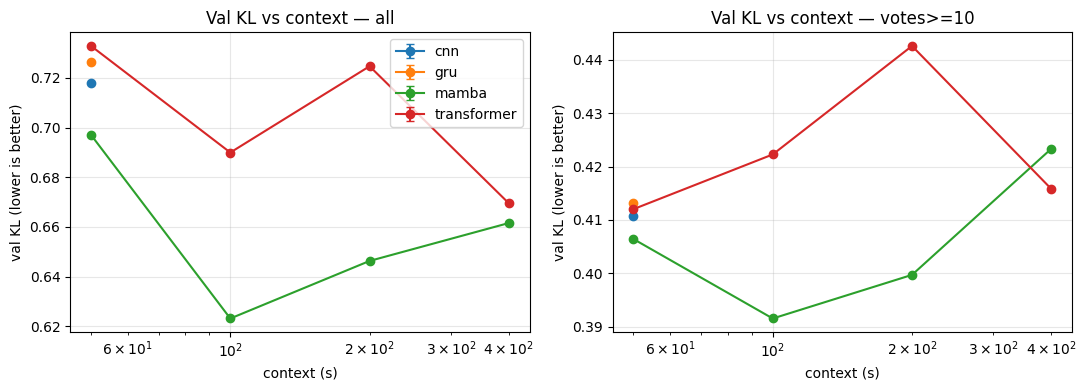

In [12]:
rows = []
for f_ in sorted(glob.glob(f"{CFG['RESULTS_DIR']}/*_ctx*_f*.json")):
    r = json.load(open(f_))
    for stage in ("stage1", "stage2"):
        if not r.get(stage):
            continue
        for subset, mt in r[stage]["metrics"].items():
            rows.append(dict(model=r["model"], ctx_sec=r["ctx_sec"], fold=r["fold"], stage=stage, subset=subset,
                             best_epoch=r[stage]["epoch"], minutes=r["minutes"], **mt))
res_df = pd.DataFrame(rows)
if len(res_df):
    res_df.to_csv(f"{CFG['RESULTS_DIR']}/summary.csv", index=False)
    summ = res_df.groupby(["stage", "subset", "model", "ctx_sec"])[["kl", "acc", "f1_macro", "auroc_macro"]].agg(["mean", "std", "count"])
    print(summ.round(4).to_string())
    try:
        import matplotlib.pyplot as plt
        fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)
        for ax, subset in zip(axes, ["all", HV]):
            sub = res_df[(res_df.stage == "stage2") & (res_df.subset == subset)]
            if sub.empty:
                sub = res_df[(res_df.stage == "stage1") & (res_df.subset == subset)]
            for name, g_ in sub.groupby("model"):
                s_ = g_.groupby("ctx_sec")["kl"].agg(["mean", "std"]).reset_index()
                ax.errorbar(s_["ctx_sec"], s_["mean"], yerr=s_["std"].fillna(0), marker="o", capsize=3, label=name)
            ax.set_xscale("log"); ax.set_xlabel("context (s)"); ax.set_ylabel("val KL (lower is better)")
            ax.set_title(f"Val KL vs context — {subset}"); ax.grid(alpha=0.3)
        axes[0].legend(); plt.tight_layout()
        plt.savefig(f"{CFG['RESULTS_DIR']}/kl_vs_context.png", dpi=150); plt.show()
    except Exception as e:
        print("plot skipped:", e)

## Offline efficiency vs context length
Batch-1 inference latency and peak memory, and peak memory of one training step (batch 8), with and without gradient checkpointing. `transformer_math` forces plain O(L²) attention; `transformer` uses PyTorch's fused attention. With the pure-PyTorch SSD these numbers measure this implementation, not Mamba's kernels — for the paper, rerun this cell with `USE_OFFICIAL_MAMBA2=True`.

                                  ms                                     peak_mb                                        
ctx_sec                         50     100    200    400    600     1200    50     100     200     400     600      1200
mode     model                                                                                                          
infer_b1 cnn                     4.9    5.3    5.1    5.1    5.2     4.9    29.7   32.6    39.3    54.4    68.8    111.5
         gru                     3.6    3.9    6.8   12.6   18.2    35.5    97.4   98.6   102.4   110.3   117.8    142.5
         mamba                  24.2   24.8   24.6   23.4   25.4    25.1    30.0   33.2    39.7    55.3    67.4    110.0
         transformer             4.8    4.7    4.7    4.9    5.0    14.4    27.7   31.6    38.3    53.4    67.7    110.5
         transformer_math        5.7    5.6    5.6   11.3   25.0    95.1    28.7   33.9    53.6   125.3   239.7    847.4
train_b8 cnn                    

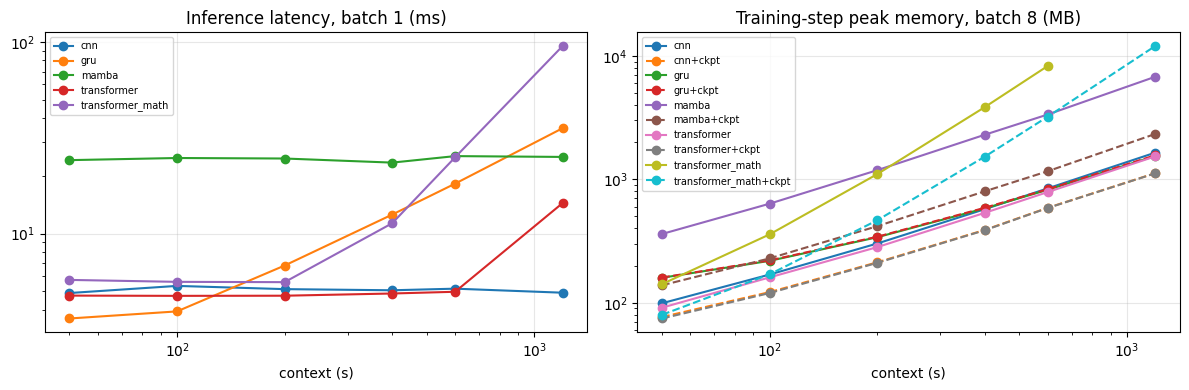

In [13]:
def bench(name, ctx, train_mode, math_attn=False, ckpt=False):
    old_ckpt = CFG["GRAD_CKPT"]; CFG["GRAD_CKPT"] = ckpt
    model = Net(name).to(DEV)
    bsz = 8 if train_mode else 1
    x = torch.randn(bsz, N_CH, ctx * CFG["FS"], device=DEV)
    m = torch.ones(bsz, ctx * CFG["FS"], device=DEV)
    ctxm = None
    if math_attn:
        from torch.nn.attention import sdpa_kernel, SDPBackend
        ctxm = sdpa_kernel(SDPBackend.MATH)
    try:
        if ctxm: ctxm.__enter__()
        if DEV.type == "cuda":
            torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()
        def step():
            with torch.autocast(device_type=DEV.type, dtype=torch.float16, enabled=CFG["AMP"] and DEV.type == "cuda"):
                if train_mode:
                    model.train(); model(x, m).float().sum().backward(); model.zero_grad(set_to_none=True)
                else:
                    model.eval()
                    with torch.no_grad():
                        model(x, m)
        step(); step()
        if DEV.type == "cuda": torch.cuda.synchronize()
        t0, reps = time.time(), 3 if train_mode else 5
        for _ in range(reps):
            step()
        if DEV.type == "cuda": torch.cuda.synchronize()
        ms = (time.time() - t0) / reps * 1000
        mem = torch.cuda.max_memory_allocated() / 2**20 if DEV.type == "cuda" else float("nan")
        return dict(ms=ms, peak_mb=mem, oom=False)
    except torch.OutOfMemoryError:
        return dict(ms=float("nan"), peak_mb=float("nan"), oom=True)
    finally:
        CFG["GRAD_CKPT"] = old_ckpt
        if ctxm: ctxm.__exit__(None, None, None)
        del model, x, m
        if DEV.type == "cuda": torch.cuda.empty_cache()

if CFG["RUN_BENCHMARK"]:
    variants = [(n_, False) for n_ in MIXERS] + [("transformer", True)]
    bench_rows = []
    for name, math_attn in variants:
        label = name + ("_math" if math_attn else "") + ("_official" if name == "mamba" and CFG["USE_OFFICIAL_MAMBA2"] else "")
        for ctx in CFG["BENCH_CTX"]:
            r = bench(name, ctx, False, math_attn)
            bench_rows.append(dict(model=label, ctx_sec=ctx, tokens=ctx * CFG["FS"] // CFG["PATCH"], mode="infer_b1", **r))
            for ck in CFG["BENCH_CKPT"]:
                r = bench(name, ctx, True, math_attn, ck)
                bench_rows.append(dict(model=label + ("+ckpt" if ck else ""), ctx_sec=ctx, tokens=ctx * CFG["FS"] // CFG["PATCH"], mode="train_b8", **r))
    bench_df = pd.DataFrame(bench_rows)
    bench_df.to_csv(f"{CFG['RESULTS_DIR']}/efficiency.csv", index=False)
    print(bench_df.pivot_table(index=["mode", "model"], columns="ctx_sec", values=["ms", "peak_mb"]).round(1).to_string())
    try:
        import matplotlib.pyplot as plt
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        for ax, val, mode, title in [(axes[0], "ms", "infer_b1", "Inference latency, batch 1 (ms)"),
                                     (axes[1], "peak_mb", "train_b8", "Training-step peak memory, batch 8 (MB)")]:
            sub = bench_df[(bench_df["mode"] == mode) & bench_df[val].notna() & (bench_df[val] > 0)]
            for name, g_ in sub.groupby("model"):
                ax.plot(g_["ctx_sec"], g_[val], marker="o", label=name, linestyle="--" if "ckpt" in name else "-")
            ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("context (s)"); ax.set_title(title); ax.grid(alpha=0.3)
            ax.legend(fontsize=7)
        plt.tight_layout(); plt.savefig(f"{CFG['RESULTS_DIR']}/efficiency.png", dpi=150); plt.show()
    except Exception as e:
        print("plot skipped:", e)

## Streaming benchmark: continuous monitoring
In deployment a causal model receives one new token every 0.25 s and must update its output. Per new token:
- **Mamba-2 (causal, recurrent form):** fixed-size state — the cost does not depend on how many hours were already seen.
- **Transformer with KV cache:** must attend over every past token; the cache grows linearly with history (memory and per-token time).
- **GRU:** also fixed-size state. Being fair here matters: the SSM's edge over RNNs is parallel training and accuracy, not streaming cost.

Weights are random (cost does not depend on them); all three use the same width and depth as the classifiers. State/cache memory is computed exactly from tensor sizes; latency is measured per token at batch 1.

                       ms_per_token                             state_kb                                        
hours                         0.25  1.00   6.00   24.00   72.00    0.25     1.00      6.00      24.00      72.00
model                                                                                                           
gru                            1.09  1.09   1.09   1.09    1.09      1.0      1.0       1.0       1.0        1.0
mamba (causal)                 3.34  3.34   3.34   3.34    3.34    280.0    280.0     280.0     280.0      280.0
transformer (KV cache)         2.25  3.89  20.33  80.50  240.94   7200.0  28800.0  172800.0  691200.0  2073600.0

real-time budget: one token every 250.0 ms


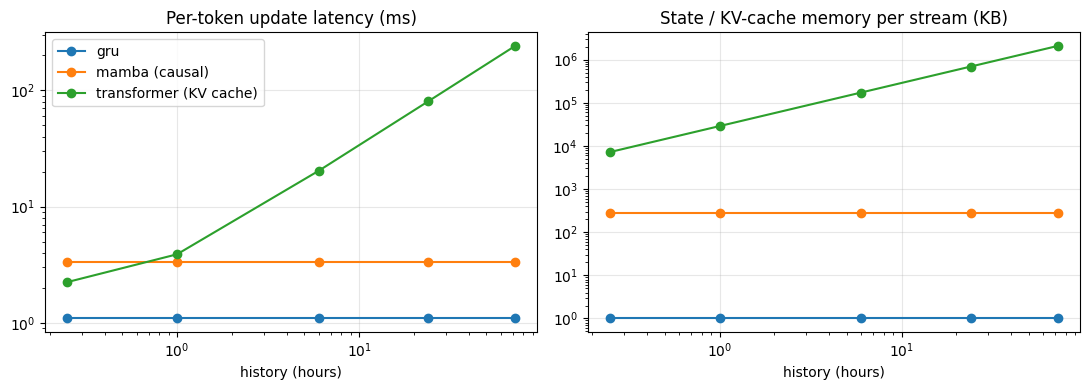

In [14]:
class CausalSSMStack(nn.Module):
    def __init__(self, d, L):
        super().__init__()
        self.norms = nn.ModuleList([nn.LayerNorm(d) for _ in range(L)])
        self.blocks = nn.ModuleList([Mamba2(d, CFG["D_STATE"], CFG["HEADDIM"], CFG["EXPAND"], CFG["CHUNK"]) for _ in range(L)])
    def init_state(self, b, device):
        return [blk.init_state(b, device) for blk in self.blocks]
    def step(self, u, states):
        new = []
        for norm, blk, st in zip(self.norms, self.blocks, states):
            y, st = blk.step(norm(u), st)
            u = u + y; new.append(st)
        return u, new

class AttnStepLayer(nn.Module):
    def __init__(self, d, H):
        super().__init__()
        self.H, self.dh = H, d // H
        self.n1, self.n2 = nn.LayerNorm(d), nn.LayerNorm(d)
        self.qkv, self.o = nn.Linear(d, 3 * d), nn.Linear(d, d)
        self.ff = nn.Sequential(nn.Linear(d, 4 * d), nn.GELU(), nn.Linear(4 * d, d))
    def step(self, x, K, V):
        q, k, v = self.qkv(self.n1(x)).chunk(3, -1)
        K[:, :, -1] = k.view(1, self.H, self.dh).to(K.dtype)        # write the new token into the (pre-allocated) cache
        V[:, :, -1] = v.view(1, self.H, self.dh).to(V.dtype)
        a = F.scaled_dot_product_attention(q.view(1, self.H, 1, self.dh).to(K.dtype), K, V)
        x = x + self.o(a.reshape(1, -1).to(x.dtype))
        return x + self.ff(self.n2(x))

@torch.no_grad()
def time_steps(fn, n_warm=20, n=200):
    for _ in range(n_warm): fn()
    if DEV.type == "cuda": torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(n): fn()
    if DEV.type == "cuda": torch.cuda.synchronize()
    return (time.time() - t0) / n * 1000

def nbytes(ts):
    return sum(t.numel() * t.element_size() for t in ts)

if CFG["RUN_STREAM_BENCH"]:
    d, L, H = CFG["D_MODEL"], CFG["N_LAYERS"], CFG["N_HEADS_ATTN"]
    amp = dict(device_type=DEV.type, dtype=torch.float16, enabled=CFG["AMP"] and DEV.type == "cuda")
    x1 = torch.randn(1, d, device=DEV)
    stream_rows = []

    ssm = CausalSSMStack(d, L).to(DEV).eval()
    st_holder = [ssm.init_state(1, DEV)]
    def ssm_step():
        with torch.autocast(**amp):
            _, st_holder[0] = ssm.step(x1, st_holder[0])
    ssm_ms = time_steps(ssm_step)
    ssm_mb = nbytes([t for st in st_holder[0] for t in st]) / 2**20

    gru = nn.GRU(d, d, L).to(DEV).eval()
    h_holder = [torch.zeros(L, 1, d, device=DEV)]
    def gru_step():
        with torch.autocast(**amp):
            _, h_holder[0] = gru(x1[None], h_holder[0])
    gru_ms = time_steps(gru_step)
    gru_mb = nbytes(h_holder) / 2**20

    attn = nn.ModuleList([AttnStepLayer(d, H) for _ in range(L)]).to(DEV).eval()
    for hours in CFG["STREAM_HOURS"]:
        n_tok = int(hours * 3600 * CFG["FS"] / CFG["PATCH"])
        stream_rows.append(dict(model="mamba (causal)", hours=hours, history_tokens=n_tok, ms_per_token=ssm_ms, state_mb=ssm_mb, oom=False))
        stream_rows.append(dict(model="gru", hours=hours, history_tokens=n_tok, ms_per_token=gru_ms, state_mb=gru_mb, oom=False))
        try:
            kv_dtype = torch.float16 if DEV.type == "cuda" else torch.float32
            K = [torch.randn(1, H, n_tok, d // H, device=DEV, dtype=kv_dtype) for _ in range(L)]
            V = [torch.randn(1, H, n_tok, d // H, device=DEV, dtype=kv_dtype) for _ in range(L)]
            def attn_step():
                x = x1
                with torch.autocast(**amp):
                    for lyr, k_, v_ in zip(attn, K, V):
                        x = lyr.step(x, k_, v_)
            ms = time_steps(attn_step, n_warm=5, n=50)
            stream_rows.append(dict(model="transformer (KV cache)", hours=hours, history_tokens=n_tok, ms_per_token=ms,
                                    state_mb=nbytes(K + V) / 2**20, oom=False))
            del K, V
        except torch.OutOfMemoryError:
            stream_rows.append(dict(model="transformer (KV cache)", hours=hours, history_tokens=n_tok, ms_per_token=float("nan"),
                                    state_mb=2 * L * n_tok * d * 2 / 2**20, oom=True))
        if DEV.type == "cuda": torch.cuda.empty_cache()

    stream_df = pd.DataFrame(stream_rows)
    stream_df["state_kb"] = stream_df["state_mb"] * 1024
    stream_df["streams_per_16GB"] = (16 * 1024 / stream_df["state_mb"]).astype(np.int64)
    stream_df.to_csv(f"{CFG['RESULTS_DIR']}/streaming.csv", index=False)
    print(stream_df.pivot_table(index="model", columns="hours", values=["ms_per_token", "state_kb"]).round(2).to_string())
    print("\nreal-time budget: one token every", CFG["PATCH"] / CFG["FS"] * 1000, "ms")
    try:
        import matplotlib.pyplot as plt
        fig, axes = plt.subplots(1, 2, figsize=(11, 4))
        for ax, val, title in [(axes[0], "ms_per_token", "Per-token update latency (ms)"), (axes[1], "state_kb", "State / KV-cache memory per stream (KB)")]:
            for name, g_ in stream_df.groupby("model"):
                ax.plot(g_["hours"], g_[val], marker="o", label=name)
            ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel("history (hours)"); ax.set_title(title); ax.grid(alpha=0.3)
        axes[0].legend(); plt.tight_layout(); plt.savefig(f"{CFG['RESULTS_DIR']}/streaming.png", dpi=150); plt.show()
    except Exception as e:
        print("plot skipped:", e)